### Missglückte Drohnenlieferung – Lösung Schritt für Schritt

*34. Bundeswettbewerb Informatik (2015/2016), 2. Runde, Aufgabe 2*

In der zukunftsorientierten Mustersiedlung Amacity stehen 100 Häuser in einem Quadrat angeordnet. Da Pakete in Zukunft vielleicht durch
kleine, fliegende Zustellroboter geliefert werden, ist ihr Dach schon mit einer geeigneten Empfangsplattform ausgestattet, auf welcher
aber nur Platz für ein großes Paket ist.

In einem einmaligen Experiment werden jetzt tatsächlich 100 Pakete an diese 100 Häuser geliefert und alle heil auf die
Empfangsplattformen abgelegt. Leider wurde eine falsche Adressenliste verwendet und die Pakete sind nicht an die richtigen Häuser
geliefert worden. Die folgende Zeichnung zeigt, wo die Pakete gelandet sind. Leider muss aber das Paket i, j tatsächlich in die i-te
Zeile und in die j-te Spalte (wobei die Nummerierung mit 0 beginnt und mit 9 endet).

*(Bild: ein Quadrat aus 10 × 10 Häusern, auf jedem steht die Nummer i, j des Pakets, das dort liegt. Dieselben Angaben stehen in
`beispieldaten/drohnen_eingabe_amacity.txt`.)*

Die Einwohner möchten jetzt die Pakete schrittweise an die richtigen Orte befördern. Dafür steigt aus jedem Haus eine Person auf das Dach.

Ein Schritt sieht dann so aus:

(a) Die Person auf dem Dach nimmt das dort liegende Paket in die Hand.

(b) Sie sieht auf einem Plan nach, ob und gegebenenfalls in welche Richtung das Paket in diesem Schritt geworfen werden soll.

(c) Das Paket wird in diese Richtung geworfen und von der Person auf dem entsprechenden Nachbarhaus aufgefangen und dann dort abgelegt.

Wichtig dabei ist natürlich, dass in (c) alle Personen, die ein Paket werfen, dies gleichzeitig tun. In einem Schritt können also bis zu
100 Pakete gleichzeitig zu einem Nachbarhaus wechseln. Nachbarhäuser sind direkt, aber nicht diagonal aneinander grenzende Häuser.
Noch wichtiger aber ist, dass der Plan garantieren muss, dass nach jedem Schritt auf jedem Haus genau ein Paket liegt.

Zur Illustration zeigen wir einen vierschrittigen Plan für eine einfachere Siedlung mit nur neun Häusern:

*(Bild: die neun Häuser vor und nach jedem der vier Schritte, mit Pfeilen für die Würfe. Derselbe Plan steht in
`beispieldaten/drohnen_ausgabe_beispiel.txt`; wir zeichnen ihn unten nach.)*

Erstelle mit Computerhilfe einen solchen Plan für die oben angegebene Paketverteilung in Amacity. Er soll übersichtlich zeigen, wer in
jedem Schritt sein Paket in welche Richtung wirft. Versuche die Anzahl der Schritte klein zu halten. Auf der BWINF-Webseite findest du
bereits einen Plan. Schaffst du es mit ähnlich vielen Schritten auszukommen? Oder kannst du sogar einen Plan mit weniger Schritten
finden?

Gib deinen Plan auch in eine Datei aus, in dem auf der Webseite spezifizierten Format. Es ist hübsch und sehr nützlich, alle Schritte zu
visualisieren – am besten in einer Animation.

#### Beispieldaten

Im Ordner `beispieldaten` stehen zwei Eingaben und zwei Pläne (eine Beschreibung des Formats gab es nicht, wir haben es aus den Dateien
abgelesen und mit dem Schiedsrichter unten bestätigt):
- `drohnen_eingabe_beispiel.txt` (9 Häuser) und `drohnen_eingabe_amacity.txt` (100 Häuser): In der ersten Zeile steht die Seitenlänge
  n, danach je Haus eine Zeile „i j a b“: Auf dem Haus in Zeile i und Spalte j liegt das Paket für das Haus a, b.
- `drohnen_ausgabe_beispiel.txt` (der Plan mit 4 Schritten aus der Aufgabe) und `drohnen_ausgabe_amacity.txt` (der Plan der
  BWINF-Webseite): je Haus eine Zeile „i j“ und dahinter ein Buchstabe pro Schritt, was die Person auf diesem Haus in dem Schritt tut:
  `N` nach Norden werfen (eine Zeile nach oben, Zeile − 1), `S` nach Süden (Zeile + 1), `O` nach Osten (Spalte + 1), `W` nach Westen
  (Spalte − 1) oder `_` nicht werfen.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Manhattan-Distanz:** Ein Paket, das |Δzeile| + |Δspalte| vom Ziel entfernt ist, braucht mindestens so viele Würfe. Die größte
  solche Entfernung ist eine **untere Schranke** für die Zahl der Schritte.
- **Simulation mit Schiedsrichter:** Jeden Plan erst nachspielen und prüfen, bevor man ihm glaubt.
- **Gieriges Verfahren (Greedy):** Schritt für Schritt das tun, was gerade am meisten bringt, ohne weiter vorauszuschauen.
- **Zuordnungsproblem** (englisch *assignment problem*): Gegeben ist eine Tabelle von Kosten „Zeile i wird Spalte j zugeordnet kostet
  c[i][j]“. Gesucht ist eine Zuordnung, bei der jede Zeile genau eine Spalte und jede Spalte genau eine Zeile bekommt und die
  Gesamtkosten am kleinsten sind. Das klassische Verfahren dafür heißt **Ungarische Methode**. Wir müssen es nicht selbst
  programmieren.

**Nützliche Funktionen und Bibliotheken**
- Dictionaries mit Tupeln als Schlüssel: `lage[(i, j)]` ist das Paket auf dem Haus in Zeile i, Spalte j.
- `sorted(liste, reverse=True)` sortiert auch Tupel, zuerst nach dem ersten Eintrag (dann nach dem zweiten usw.), hier absteigend.
- `numpy.full((zeilen, spalten), wert)` legt eine Tabelle an, in der überall `wert` steht.
- `scipy.optimize.linear_sum_assignment(kosten)` löst das Zuordnungsproblem für eine Kostentabelle und gibt zwei Listen zurück:
  Zeile `zeilen[k]` wird Spalte `spalten[k]` zugeordnet.
- `matplotlib`: `imshow` zeichnet eine Tabelle als farbiges Bild, `quiver` zeichnet Pfeile.

## Die Idee in Worten

1. **Einlesen und Schiedsrichter.** Wir lesen die Paketverteilung und die beiden Pläne ein und spielen die Pläne nach. Dabei prüfen
   wir, dass nach jedem Schritt auf jedem Haus genau ein Paket liegt und am Ende alle Pakete am Ziel sind.
2. **Wie gut kann ein Plan höchstens sein?** Ein Paket kommt pro Schritt nur ein Haus weiter. Das Paket mit der größten Entfernung zum
   Ziel bestimmt also, wie viele Schritte man mindestens braucht. In Amacity sind das 15.
3. **Version 1: nur Tauschen.** Zwei Nachbarn werfen sich gegenseitig ihr Paket zu. Wir bewerten jeden möglichen Tausch und nehmen
   gierig die besten, die sich nicht in die Quere kommen. Das bleibt stecken.
4. **Version 2: ein Schritt ist eine Zuordnung.** Jedes Haus gibt sein Paket an sich selbst oder an einen Nachbarn, und jedes Haus
   bekommt genau ein Paket. Das ist ein Zuordnungsproblem, und `linear_sum_assignment` findet in jedem Schritt die beste Zuordnung,
   auch mit Tauschen, Ringen und langen Wurfkreisen. Entscheidend ist, wie wir einen Schritt bewerten: Pakete, die weit vom Ziel
   entfernt sind, müssen Vorrang haben. Mit der richtigen Bewertung schaffen wir Amacity in **15 Schritten**, also so schnell, wie es
   überhaupt geht.
5. **Ausgabe:** der Plan als Pfeilbilder, als Datei im Format der Webseite und als Bildfolge.
6. **Für Neugierige** und **zum Schluss:** andere Bewertungen, eine Engstelle, Zufallsstädte und ein MiniZinc-Modell.

## Schritt 1: Einlesen

`lies_eingabe` gibt die Seitenlänge `n` und das Dictionary `lage` zurück: `lage[(i, j)] = (a, b)` heißt, auf dem Haus in Zeile i und
Spalte j liegt das Paket für das Haus a, b. `zeige_lage` druckt die Verteilung als Tabelle; ein Punkt steht für ein Paket, das schon am
richtigen Ort liegt.

In [ ]:
def lies_eingabe(dateiname):
    with open('beispieldaten/' + dateiname, encoding='utf-8') as datei:
        zeilen = datei.read().split('\n')
    n = int(zeilen[0])
    lage = {}
    for zeile in zeilen[1:]:
        teile = zeile.split()
        if len(teile) == 4:
            i, j, a, b = [int(x) for x in teile]
            lage[(i, j)] = (a, b)                       # auf Haus (i, j) liegt das Paket für Haus (a, b)
    return n, lage


def zeige_lage(n, lage):
    for i in range(n):
        teile = []
        for j in range(n):
            a, b = lage[(i, j)]
            if (a, b) == (i, j):
                teile.append('  . ')                    # Paket liegt schon richtig
            else:
                teile.append(f' {a},{b}')
        print(''.join(teile))


EINGABEN = {'beispiel': 'drohnen_eingabe_beispiel.txt', 'amacity': 'drohnen_eingabe_amacity.txt'}
stadt = {}
for name in EINGABEN:
    stadt[name] = lies_eingabe(EINGABEN[name])
    n, lage = stadt[name]
    falsch = 0
    for haus in lage:
        if lage[haus] != haus:
            falsch = falsch + 1
    print(f'{name}: {n} x {n} Häuser, {falsch} Pakete liegen falsch')
print()
zeige_lage(*stadt['beispiel'])

beispiel: 3 x 3 Häuser, 6 Pakete liegen falsch
amacity: 10 x 10 Häuser, 97 Pakete liegen falsch

 0,1 1,0  . 
 1,1 2,0  . 
 2,2  .  0,0


Im kleinen Beispiel liegen drei Pakete schon richtig. Das Paket für das Haus 0,0 liegt ganz unten rechts auf dem Haus 2,2.

## Schritt 2: Pläne einlesen und der Schiedsrichter

Einen Plan speichern wir als Liste von Schritten. Ein Schritt ist ein Dictionary, das jedem **werfenden** Haus seine Richtung zuordnet,
zum Beispiel `{(0, 0): 'O', (0, 1): 'W'}` für einen Tausch zwischen 0,0 und 0,1. Häuser, die nicht werfen, kommen nicht vor.
`RICHTUNG` übersetzt die Buchstaben in die Änderung von Zeile und Spalte.

`fuehre_schritt_aus` wirft alle Pakete gleichzeitig: Jedes Haus gibt sein Paket ab (an das Nachbarhaus oder an sich selbst, wenn es
nicht wirft). Landet nie ein Paket auf einem Haus, das schon eines bekommen hat, dann hat am Ende jedes Haus genau ein Paket, denn es
gibt genauso viele Pakete wie Häuser. Bei einem Fehler gibt die Funktion statt der neuen Lage einen Text zurück. `pruefe_plan` führt
alle Schritte aus und prüft am Ende, ob jedes Paket an seinem Ziel liegt.

In [ ]:
RICHTUNG = {'N': (-1, 0), 'S': (1, 0), 'O': (0, 1), 'W': (0, -1)}


def plan_aus_text(text):
    """Liest einen Plan im Format der Webseite: je Haus 'i j' und ein Buchstabe pro Schritt."""
    zeilen = {}
    for zeile in text.split('\n'):
        teile = zeile.split()
        if len(teile) == 3:
            zeilen[(int(teile[0]), int(teile[1]))] = teile[2]
    anzahl = len(zeilen[(0, 0)])                        # alle Zeilen haben gleich viele Buchstaben
    plan = []
    for k in range(anzahl):
        schritt = {}
        for haus in zeilen:
            if zeilen[haus][k] != '_':
                schritt[haus] = zeilen[haus][k]
        plan.append(schritt)
    return plan


def lies_plan(dateiname):
    with open('beispieldaten/' + dateiname, encoding='utf-8') as datei:
        return plan_aus_text(datei.read())


def fuehre_schritt_aus(n, lage, schritt):
    """Gibt die neue Lage nach dem Schritt zurück oder einen Text, wenn der Schritt nicht erlaubt ist."""
    neu = {}
    for haus in lage:
        if haus in schritt:
            dz, ds = RICHTUNG[schritt[haus]]
            wohin = (haus[0] + dz, haus[1] + ds)
            if not (0 <= wohin[0] < n and 0 <= wohin[1] < n):
                return f'Haus {haus} wirft aus der Siedlung hinaus'
        else:
            wohin = haus                                # wer nicht wirft, behält sein Paket
        if wohin in neu:
            return f'auf Haus {wohin} landen zwei Pakete'
        neu[wohin] = lage[haus]
    return neu


def pruefe_plan(n, lage, plan):
    for k in range(len(plan)):
        lage = fuehre_schritt_aus(n, lage, plan[k])
        if isinstance(lage, str):                       # ein Text: der Schritt war nicht erlaubt
            return f'Fehler in Schritt {k + 1}: {lage}'
    falsch = 0
    for haus in lage:
        if lage[haus] != haus:
            falsch = falsch + 1
    if falsch > 0:
        return f'am Ende liegen {falsch} Pakete falsch'
    return 'ok'


def anzahl_wuerfe(plan):
    summe = 0
    for schritt in plan:
        summe = summe + len(schritt)
    return summe


PLAENE = {'beispiel': 'drohnen_ausgabe_beispiel.txt', 'amacity': 'drohnen_ausgabe_amacity.txt'}
bwinf_plan = {}
for name in PLAENE:
    bwinf_plan[name] = lies_plan(PLAENE[name])
    n, lage = stadt[name]
    plan = bwinf_plan[name]
    print(f'{name}: {len(plan)} Schritte, {anzahl_wuerfe(plan)} Würfe, Schiedsrichter: {pruefe_plan(n, lage, plan)}')

beispiel: 4 Schritte, 20 Würfe, Schiedsrichter: ok
amacity: 41 Schritte, 1276 Würfe, Schiedsrichter: ok


Beide Pläne sind in Ordnung. Damit ist auch die Bedeutung der Buchstaben bestätigt: Mit vertauschten Richtungen würden Pakete aus der
Siedlung fliegen oder zwei Pakete auf demselben Haus landen. Der Schiedsrichter merkt auch Fehler, zum Beispiel wenn zwei Häuser auf dasselbe Haus
werfen oder jemand über den Rand wirft:

In [ ]:
n, lage = stadt['beispiel']
print(pruefe_plan(n, lage, [{(0, 0): 'S', (2, 0): 'N'}]))
print(pruefe_plan(n, lage, [{(0, 0): 'N'}]))
print(pruefe_plan(n, lage, [{(0, 0): 'O', (0, 1): 'W'}]))

Fehler in Schritt 1: auf Haus (1, 0) landen zwei Pakete
Fehler in Schritt 1: Haus (0, 0) wirft aus der Siedlung hinaus
am Ende liegen 5 Pakete falsch


## Schritt 3: Wie viele Schritte braucht man mindestens?

Der **Abstand** eines Pakets zu seinem Ziel ist die Zahl der Würfe, die es mindestens noch braucht: die Differenz der Zeilen plus die
Differenz der Spalten (Manhattan-Distanz, wie die Wege in einer Stadt mit rechtwinkligen Straßen). Weil ein Paket in einem Schritt
höchstens ein Haus weiterkommt, braucht jeder Plan mindestens so viele Schritte, wie das am weitesten entfernte Paket Abstand hat.
Die Summe aller Abstände ist entsprechend eine untere Schranke für die Zahl der **Würfe**.

In [ ]:
def abstand(haus, ziel):
    return abs(haus[0] - ziel[0]) + abs(haus[1] - ziel[1])


def untere_schranke(lage):
    groesster = 0
    for haus in lage:
        groesster = max(groesster, abstand(haus, lage[haus]))
    return groesster


def summe_abstaende(lage):
    summe = 0
    for haus in lage:
        summe = summe + abstand(haus, lage[haus])
    return summe


for name in stadt:
    n, lage = stadt[name]
    weitestes = []
    for haus in lage:
        if abstand(haus, lage[haus]) == untere_schranke(lage):
            weitestes.append(f'Paket {lage[haus]} auf Haus {haus}')
    print(f'{name}: mindestens {untere_schranke(lage)} Schritte und {summe_abstaende(lage)} Würfe;',
          'am weitesten:', ', '.join(weitestes))

beispiel: mindestens 4 Schritte und 12 Würfe; am weitesten: Paket (0, 0) auf Haus (2, 2)
amacity: mindestens 15 Schritte und 654 Würfe; am weitesten: Paket (0, 9) auf Haus (6, 0)


Der Plan für das kleine Beispiel braucht 4 Schritte und ist damit so kurz wie möglich (er braucht aber 20 statt 12 Würfe). Der Plan der
BWINF-Webseite für Amacity braucht 41 Schritte, mindestens nötig sind 15. Das Paket für das Haus 0,9 liegt auf dem Haus 6,0, also 6
Zeilen und 9 Spalten entfernt. Die Lösungshinweise nennen dieselbe Schranke 15 und sagen, dass sie für Amacity tatsächlich erreichbar
ist. Bei manchen Verteilungen geht das nicht (siehe „Für Neugierige“).

## Schritt 4: Den Plan übersichtlich zeigen und als Datei schreiben

`zeige_plan` druckt ausgewählte Schritte nebeneinander, jeden als Raster mit Pfeilen (`·` heißt: nicht werfen). `plan_als_text`
schreibt einen Plan im Format der Webseite, damit wir unsere Pläne später auch in Dateien ausgeben können. Zur Probe schreiben wir den
Plan des kleinen Beispiels und lesen ihn mit `plan_aus_text` wieder ein.

In [ ]:
PFEIL = {'N': '↑', 'S': '↓', 'O': '→', 'W': '←'}


def zeige_plan(n, plan, nummern):
    """Druckt die Schritte mit den angegebenen Nummern (ab 1) nebeneinander."""
    breite = max(2 * n + 2, 12)                         # Breite einer Spalte in Zeichen
    kopf = []
    for k in nummern:
        kopf.append(f'Schritt {k}'.ljust(breite))
    print(''.join(kopf))
    for i in range(n):
        teile = []
        for k in nummern:
            schritt = plan[k - 1]
            zeile = ''
            for j in range(n):
                if (i, j) in schritt:
                    zeile = zeile + PFEIL[schritt[(i, j)]] + ' '
                else:
                    zeile = zeile + '· '
            teile.append(zeile.ljust(breite))
        print(''.join(teile))


def plan_als_text(n, plan):
    zeilen = []
    for j in range(n):                                  # Reihenfolge wie in den Dateien der Webseite: Spalte für Spalte
        for i in range(n):
            buchstaben = ''
            for schritt in plan:
                if (i, j) in schritt:
                    buchstaben = buchstaben + schritt[(i, j)]
                else:
                    buchstaben = buchstaben + '_'
            zeilen.append(f'{i} {j} {buchstaben}')
    return '\n'.join(zeilen)


n, lage = stadt['beispiel']
zeige_plan(n, bwinf_plan['beispiel'], [1, 2, 3, 4])
text = plan_als_text(n, bwinf_plan['beispiel'])
print()
print(text)
print('wieder eingelesen gleich:', plan_aus_text(text) == bwinf_plan['beispiel'])

Schritt 1   Schritt 2   Schritt 3   Schritt 4   
· → ←       · · ↓       · → ←       → ← ·       
· ↓ ←       · · ↑       · → ←       → ← ·       
· → ↑       → ← ·       · → ←       · · ·       

0 0 ___O
1 0 ___O
2 0 _O__
0 1 O_OW
1 1 S_OW
2 1 OWO_
0 2 WSW_
1 2 WNW_
2 2 N_W_
wieder eingelesen gleich: True


Im ersten Schritt tauschen 0,1 und 0,2 ihre Pakete, und die vier Häuser rechts unten werfen im Kreis (ein **Wurfkreis**). In jedem Schritt besteht
der Plan aus solchen Kreisen: Wer ein Paket wegwirft, muss auch eines bekommen. Ein Tausch ist der kleinste Kreis.

## Schritt 5: Version 1 – nur Tauschen

Ein Tausch zwischen zwei Nachbarn ist der einfachste erlaubte Schritt, und Tausche, die keine gemeinsamen Häuser haben, darf man im
selben Schritt ausführen. Welche Tausche sollen wir nehmen? Wir geben jedem Paket **Kosten**, die von seinem Abstand d zum Ziel abhängen,
zunächst einfach `kosten(d) = d`. Ein Tausch ist gut, wenn die Kosten der beiden Pakete danach kleiner sind als vorher; der Unterschied
ist sein **Gewinn**. Gierig nehmen wir die Tausche mit dem größten Gewinn, solange sie keine schon benutzten Häuser brauchen.

`paketkosten(haus, ziel)` sind die Kosten eines Pakets für das Haus `ziel`, wenn es auf dem Haus `haus` liegt (in „Für Neugierige“
probieren wir damit andere Bewertungen aus). `nachbarn` liefert die Nachbarhäuser, `richtung` den Buchstaben für einen Wurf von einem Haus zum Nachbarn. Die Funktion
`naechster_schritt` legt fest, welche Version `finde_plan` benutzt (wir definieren sie später neu). `finde_plan` hört auf, wenn alles
richtig liegt, oder wenn ein Schritt die Gesamtkosten nicht mehr senkt: Dann steckt das Verfahren fest.

In [ ]:
def kosten(d):
    return d


def paketkosten(haus, ziel):
    """Kosten eines Pakets für das Haus ziel, wenn es auf dem Haus haus liegt."""
    return kosten(abstand(haus, ziel))


def gesamtkosten(lage):
    summe = 0
    for haus in lage:
        summe = summe + paketkosten(haus, lage[haus])
    return summe


def nachbarn(n, haus):
    i, j = haus
    liste = []
    for dz, ds in [(-1, 0), (1, 0), (0, 1), (0, -1)]:
        if 0 <= i + dz < n and 0 <= j + ds < n:
            liste.append((i + dz, j + ds))
    return liste


def richtung(von, nach):
    for buchstabe in RICHTUNG:
        dz, ds = RICHTUNG[buchstabe]
        if (von[0] + dz, von[1] + ds) == nach:
            return buchstabe


def schritt_tauschen(n, lage):
    kandidaten = []
    for a in lage:
        for b in [(a[0], a[1] + 1), (a[0] + 1, a[1])]:  # rechter und unterer Nachbar: jedes Paar nur einmal
            if b in lage:
                vorher = paketkosten(a, lage[a]) + paketkosten(b, lage[b])
                nachher = paketkosten(b, lage[a]) + paketkosten(a, lage[b])
                if nachher < vorher:
                    kandidaten.append((vorher - nachher, a, b))
    schritt = {}
    for gewinn, a, b in sorted(kandidaten, reverse=True):   # größter Gewinn zuerst
        if a not in schritt and b not in schritt:       # beide Häuser noch frei
            schritt[a] = richtung(a, b)
            schritt[b] = richtung(b, a)
    return schritt


def naechster_schritt(n, lage):
    return schritt_tauschen(n, lage)


def finde_plan(n, lage, max_schritte=200):
    plan = []
    while untere_schranke(lage) > 0 and len(plan) < max_schritte:
        schritt = naechster_schritt(n, lage)
        neu = fuehre_schritt_aus(n, lage, schritt)
        if gesamtkosten(neu) >= gesamtkosten(lage):     # kein Fortschritt mehr: steckt fest
            break
        plan.append(schritt)
        lage = neu
    return plan, lage


def teste_version():
    for name in stadt:
        n, lage = stadt[name]
        plan, ende = finde_plan(n, lage)
        falsch = 0
        for haus in ende:
            if ende[haus] != haus:
                falsch = falsch + 1
        if falsch == 0:
            print(f'{name}: fertig nach {len(plan)} Schritten mit {anzahl_wuerfe(plan)} Würfen,',
                  'Schiedsrichter:', pruefe_plan(n, lage, plan))
        else:
            print(f'{name}: steckt nach {len(plan)} Schritten fest, {falsch} Pakete liegen noch falsch,',
                  f'größter Abstand {untere_schranke(ende)}')


teste_version()

beispiel: steckt nach 1 Schritten fest, 4 Pakete liegen noch falsch, größter Abstand 4
amacity: steckt nach 12 Schritten fest, 80 Pakete liegen noch falsch, größter Abstand 13


Mit diesen Kosten bringt ein Tausch nur dann etwas, wenn **beide** Pakete näher an ihr Ziel kommen. Das gibt es bald nicht mehr. Ein
Tausch, bei dem ein weit entferntes Paket einen Schritt vorankommt und dafür ein fast angekommenes Paket einen Schritt zurück muss, hat
den Gewinn 0. Er kann aber sehr sinnvoll sein, denn das weit entfernte Paket bestimmt, wie lange wir insgesamt brauchen.

Deshalb sollen weit entfernte Pakete **Vorrang** haben: Die Kosten sollen mit dem Abstand schneller als gleichmäßig wachsen, zum Beispiel
`kosten(d) = d³`. Dann kostet ein Paket mit Abstand 15 schon 3375, eines mit Abstand 1 nur 1, und ein Wurf von 15 auf 14 bringt 631,
während ein Wurf von 1 auf 2 nur 7 kostet.

In [ ]:
def kosten(d):
    return d ** 3


teste_version()

beispiel: fertig nach 4 Schritten mit 14 Würfen, Schiedsrichter: ok
amacity: steckt nach 22 Schritten fest, 85 Pakete liegen noch falsch, größter Abstand 4


Das kleine Beispiel schafft Version 1 jetzt in 4 Schritten, so schnell wie möglich. In Amacity ist der größte Abstand von 15 auf 4
gesunken, aber das Verfahren steckt nach 22 Schritten fest. So sieht Amacity in diesem Moment aus (Abstand jedes Pakets zu seinem Ziel,
Punkt = am Ziel), dazu die drei besten Tausche, die es noch gibt:

In [ ]:
n, lage = stadt['amacity']
plan_v1, ende_v1 = finde_plan(n, lage)
for i in range(n):
    zeile = ''
    for j in range(n):
        d = abstand((i, j), ende_v1[(i, j)])
        if d == 0:
            zeile = zeile + ' .'
        else:
            zeile = zeile + f' {d}'
    print(zeile)
print()
tausche = []
for a in ende_v1:
    for b in [(a[0], a[1] + 1), (a[0] + 1, a[1])]:
        if b in ende_v1:
            vorher = paketkosten(a, ende_v1[a]) + paketkosten(b, ende_v1[b])
            nachher = paketkosten(b, ende_v1[a]) + paketkosten(a, ende_v1[b])
            tausche.append((vorher - nachher, a, b))
for gewinn, a, b in sorted(tausche, reverse=True)[:3]:
    print(f'Tausch {a} mit {b}: Gewinn {gewinn}, Pakete {ende_v1[a]} und {ende_v1[b]}')

 . . 3 2 2 1 2 . . .
 1 1 2 3 2 1 1 . . 1
 1 2 2 2 3 1 1 1 1 1
 1 2 1 4 2 2 3 2 1 2
 . 1 3 3 2 2 3 2 1 1
 . 1 3 1 1 1 3 1 2 1
 . 1 3 1 1 1 3 1 2 3
 . 1 1 2 2 3 2 2 2 2
 . . 1 2 2 2 2 1 2 3
 . 1 1 2 1 . 2 1 2 1

Tausch (9, 7) mit (9, 8): Gewinn 0, Pakete (8, 7) und (9, 6)
Tausch (9, 2) mit (9, 3): Gewinn 0, Pakete (8, 2) und (9, 1)
Tausch (8, 7) mit (8, 8): Gewinn 0, Pakete (8, 6) und (9, 7)


Der beste Tausch hat nur noch den Gewinn 0. Beim ersten liegt auf 9,7 das Paket für 8,7 (Abstand 1) und auf 9,8 das Paket für 9,6
(Abstand 2). Nach dem Tausch hat das Paket für 9,6 den Abstand 1, das Paket für 8,7 aber den Abstand 2: Kosten 1 + 8 vorher und 8 + 1
nachher. Besser wäre eine **Kette**: Das Paket für 9,6 rückt nach Westen auf 9,7, das Paket für 8,7 von dort nach Norden auf 8,7, das
Paket, das dort liegt, ein Haus weiter in Richtung seines Ziels, und so weiter. Schließt sich die Kette zu einem **Wurfkreis**, dann
kommt jedes Paket im Kreis seinem Ziel näher. Solche längeren Kreise findet ein Verfahren, das nur tauscht, nicht. Die Lösungshinweise suchen deshalb
Wurfkreise bis zur Länge 12 und kombinieren sie; wir machen es im nächsten Schritt anders.

## Schritt 6: Version 2 – ein Schritt ist eine Zuordnung

Statt Kreise einzeln zu suchen, betrachten wir einen ganzen Schritt auf einmal. In einem Schritt gibt **jedes Haus** sein Paket an
**ein** Haus weiter: an sich selbst (nicht werfen) oder an einen Nachbarn. Und **jedes Haus** bekommt genau **ein** Paket. Das ist
genau ein Zuordnungsproblem: Die Zeilen der Tabelle sind die Häuser, von denen ein Paket kommt, die Spalten die Häuser, auf denen es
landet. In die Tabelle schreiben wir die Kosten, die das Paket von `von` danach auf `nach` hat: `paketkosten(nach, lage[von])`. Unmögliche Würfe (zu weit
weg) bekommen riesige Kosten `VERBOTEN`, damit sie nie gewählt werden; „nicht werfen“ ist immer möglich, eine erlaubte Zuordnung gibt
es also immer.

Jede Zuordnung, die nur erlaubte Würfe benutzt, ist ein gültiger Schritt: Jedes Paket fliegt höchstens ein Haus weit, und auf jedem Haus
landet genau eines. Die Wurfkreise (Tausche, Ringe, lange Ketten, die sich schließen) ergeben sich von selbst.
`linear_sum_assignment` findet die Zuordnung mit den kleinsten Gesamtkosten, also den besten Schritt nach unserer Bewertung.

Die Häuser nummerieren wir dafür mit 0 bis n² − 1: `haeuser[k]` ist das Haus mit der Nummer `k`, `nummer[haus]` umgekehrt die Nummer.

In [ ]:
import numpy as np
from scipy.optimize import linear_sum_assignment

VERBOTEN = 10 ** 9


def schritt_zuordnung(n, lage):
    haeuser = sorted(lage)
    nummer = {}
    for k in range(len(haeuser)):
        nummer[haeuser[k]] = k
    tabelle = np.full((len(haeuser), len(haeuser)), VERBOTEN)
    for von in haeuser:
        for nach in [von] + nachbarn(n, von):           # behalten oder zu einem Nachbarn werfen
            tabelle[nummer[von], nummer[nach]] = paketkosten(nach, lage[von])
    zeilen, spalten = linear_sum_assignment(tabelle)
    schritt = {}
    for k in range(len(zeilen)):
        von = haeuser[zeilen[k]]
        nach = haeuser[spalten[k]]
        if von != nach:
            schritt[von] = richtung(von, nach)
    return schritt


def naechster_schritt(n, lage):
    return schritt_zuordnung(n, lage)


def kosten(d):
    return d


teste_version()

beispiel: fertig nach 5 Schritten mit 18 Würfen, Schiedsrichter: ok
amacity: steckt nach 28 Schritten fest, 5 Pakete liegen noch falsch, größter Abstand 7


Mit den einfachen Kosten `kosten(d) = d` kommt Version 2 weiter als Version 1, steckt in Amacity aber nach 28 Schritten fest: Es gibt
dann **keinen** Schritt mehr, der die Summe der Abstände verkleinert (die Zuordnung findet ja den besten). Lässt man auch Schritte zu,
die die Summe gleich lassen, wird das Verfahren in diesem Fall nach 37 Schritten fertig, aber dafür gibt es keine Garantie: Es könnte
auch endlos hin und her werfen. Jetzt geben wir weit entfernten Paketen Vorrang wie oben:

In [ ]:
for hoch in [2, 3]:
    def kosten(d):
        return d ** hoch
    print(f'kosten(d) = d hoch {hoch}:')
    teste_version()

kosten(d) = d hoch 2:
beispiel: fertig nach 4 Schritten mit 22 Würfen, Schiedsrichter: ok
amacity: fertig nach 18 Schritten mit 1054 Würfen, Schiedsrichter: ok
kosten(d) = d hoch 3:
beispiel: fertig nach 4 Schritten mit 22 Würfen, Schiedsrichter: ok
amacity: fertig nach 15 Schritten mit 1004 Würfen, Schiedsrichter: ok


Mit `d³` braucht der Plan für Amacity **15 Schritte**, genau so viele wie die untere Schranke. Einen kürzeren Plan kann es nicht geben,
unser Plan ist also **optimal**. Zum Vergleich: Der Plan der Webseite braucht 41 Schritte, das ausführlich beschriebene Verfahren der
Lösungshinweise (Wurfkreise bis Länge 12 suchen und gierig kombinieren) 34. Die Hinweise erwähnen außerdem Pläne mit 17 Schritten aus
stärker heuristischen Verfahren und sagen, dass 15 möglich ist, ohne einen solchen Plan zu zeigen.

Warum hilft `d³`? In jedem Schritt muss jedes Paket mit dem größten Abstand (die Lösungshinweise nennen sie **Alphapakete**) einen
Schritt näher kommen, sonst sinkt die Schranke nicht. Mit `d³` ist es viel teurer, ein solches Paket liegen zu lassen, als viele fast
angekommene Pakete etwas zurückzuschicken. Die Zuordnung schafft es dann in jedem Schritt, alle Alphapakete voranzubringen, und sie
achtet zugleich darauf, dass Pakete mit dem nächstkleineren Abstand (die **Betapakete**) nicht zurückfallen. Das zeigt der größte
Abstand nach jedem Schritt:

In [ ]:
def kosten(d):
    return d ** 3


n, lage = stadt['amacity']
unser_plan, ende = finde_plan(n, lage)
groesste = [untere_schranke(lage)]
for schritt in unser_plan:
    lage = fuehre_schritt_aus(n, lage, schritt)
    groesste.append(untere_schranke(lage))
print('größter Abstand nach jedem Schritt:', groesste)
wuerfe_je_schritt = []
for schritt in unser_plan:
    wuerfe_je_schritt.append(len(schritt))
print('Würfe je Schritt:', wuerfe_je_schritt)
print('Würfe:', anzahl_wuerfe(unser_plan), ' Schiedsrichter:', pruefe_plan(n, stadt['amacity'][1], unser_plan))
print()
zeige_plan(n, unser_plan, [1, 2, 15])

größter Abstand nach jedem Schritt: [15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
Würfe je Schritt: [88, 88, 90, 86, 80, 82, 70, 72, 66, 58, 62, 68, 56, 28, 10]
Würfe: 1004  Schiedsrichter: ok

Schritt 1             Schritt 2             Schritt 15            
→ → ↓ · → ← ↓ ← ← ←   → ← → → ↓ · · ↓ → ←   · · · · · · · · → ←   
↑ ← ← → ← · → → ↓ ↑   ↓ · ↑ · ↓ → ↓ ↑ · ↓   · · · · → ← · · · ·   
↓ · ↓ ← ← ← · · → ↑   ↑ ↓ ↑ ← ← ↑ ← → ← ↑   · · · · · · · · · ·   
↑ ↓ → → → ↑ ↓ ↓ · ·   ↓ ↑ → → → → → ↓ ↓ ↓   · · · · · · · · · ·   
↓ ↑ → ← → ← ↑ ↑ ↓ ↓   ↑ ↓ ↑ → ← ↓ ← ↓ ↑ ↑   · · · · · · · · · ·   
↑ · → → → → ↓ ↓ ↑ ↑   · ↑ ↑ · ↓ → ↑ → → ↓   · · · · · · · · · ·   
→ ← ↑ · ↓ ← ↓ ↑ → ←   · → ↑ ↓ ↑ · ↓ ← ↓ ↓   · · · · · · → ← · ·   
· · ↑ ← → ↑ → → → ↓   · ↑ ← ↑ ↓ ← ← ↑ ↑ ↓   · · · · → ← · → ← ·   
↓ ← ↓ ↑ ← → ← → ← ↓   ↓ → ↑ · → → → ↑ ↓ ←   · · · · · · · · · ·   
→ ↑ ↑ · ↑ ← ← ← ← ←   ↑ ↑ ← ← ← ← ← ← ← ·   · · · · · · · · · ·   


Der größte Abstand sinkt in jedem Schritt um 1. Im ersten Schritt werfen schon fast alle Häuser, oft in langen Wurfkreisen, zum Beispiel
oben links 0,0 → 0,1 → 0,2 → 1,2 → 1,1 → 1,0 → 0,0. Im letzten Schritt kommen die restlichen Pakete durch fünf Tausche an.

Auf die Zahl der **Würfe** haben wir nicht geachtet: Unser Plan braucht 1004, der Plan der Webseite 1276, mindestens nötig sind 654 (die
Summe der Abstände). Viele Pakete werden also auch einmal vom Ziel weg geworfen, um anderen Platz zu machen.

**Die Datei.** Den Plan im Format der Webseite schreibt `plan_als_text`. Hier die ersten Zeilen und eine Probe:

In [ ]:
n, lage = stadt['amacity']
text = plan_als_text(n, unser_plan)
print('\n'.join(text.split('\n')[:5]))
print('...')
print('Schiedsrichter für den wieder eingelesenen Text:', pruefe_plan(n, lage, plan_aus_text(text)))

0 0 OO___S_SO______
1 0 NS_OONSN_S_____
2 0 SNSNN_N_SN___S_
3 0 NSNSNS_SN___SN_
4 0 SNSS_NSNS__SN__
...
Schiedsrichter für den wieder eingelesenen Text: ok


In eine Datei schreibt man den Text mit:

```python
with open('drohnen_ausgabe_amacity_15.txt', 'w', encoding='utf-8') as datei:
    datei.write(plan_als_text(n, unser_plan))
```

## Schritt 7: Bildfolge statt Animation

Für eine Animation zeichnen wir jeden Schritt als Bild: Die Farbe eines Hauses zeigt den Abstand seines Pakets zum Ziel (hell = am Ziel,
dunkel = weit weg), die Pfeile die Würfe in diesem Schritt. Hintereinander angesehen ergeben die Bilder ein Daumenkino. Zuerst das
kleine Beispiel mit dem Plan der Aufgabe, dann einige Schritte unseres Plans für Amacity.

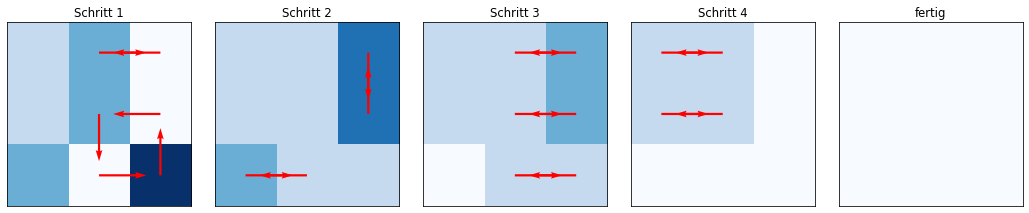

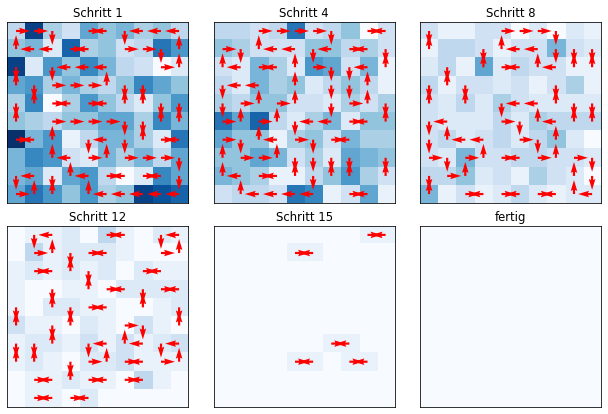

In [ ]:
import matplotlib.pyplot as plt


def zeichne_schritt(achse, n, lage, schritt, titel, hoechster):
    abstaende = []
    for i in range(n):
        zeile = []
        for j in range(n):
            zeile.append(abstand((i, j), lage[(i, j)]))
        abstaende.append(zeile)
    achse.imshow(abstaende, cmap='Blues', vmin=0, vmax=hoechster)
    x, y, dx, dy = [], [], [], []
    for haus in schritt:
        dz, ds = RICHTUNG[schritt[haus]]
        x.append(haus[1])
        y.append(haus[0])
        dx.append(ds)
        dy.append(dz)
    if len(x) > 0:
        achse.quiver(x, y, dx, dy, angles='xy', scale_units='xy', scale=1.3, color='red', width=0.012)
    achse.set_title(titel)
    achse.set_xticks([])
    achse.set_yticks([])


def zeichne_plan(n, lage, plan, nummern, spalten):
    hoechster = untere_schranke(lage)
    zeilen = (len(nummern) + spalten - 1) // spalten
    fig, achsen = plt.subplots(zeilen, spalten, figsize=(3 * spalten, 3 * zeilen))
    achsen = np.array(achsen).reshape(-1)
    k = 0
    for nummer in range(1, len(plan) + 2):              # vor Schritt 1, ..., vor Schritt len(plan), am Ende
        if nummer in nummern:
            if nummer <= len(plan):
                zeichne_schritt(achsen[k], n, lage, plan[nummer - 1], f'Schritt {nummer}', hoechster)
            else:
                zeichne_schritt(achsen[k], n, lage, {}, 'fertig', hoechster)
            k = k + 1
        if nummer <= len(plan):
            lage = fuehre_schritt_aus(n, lage, plan[nummer - 1])
    for rest in range(k, len(achsen)):
        achsen[rest].axis('off')
    plt.tight_layout()
    plt.show()


n, lage = stadt['beispiel']
zeichne_plan(n, lage, bwinf_plan['beispiel'], [1, 2, 3, 4, 5], 5)
n, lage = stadt['amacity']
zeichne_plan(n, lage, unser_plan, [1, 4, 8, 12, 15, 16], 3)

Im Laufe der Schritte wird das Bild immer heller. Am Anfang werfen fast alle Häuser gleichzeitig, gegen Ende immer weniger. In Jupyter kann man
die Bilder auch einzeln mit einem Schieberegler durchblättern, zum Beispiel mit `ipywidgets.interact`; das funktioniert aber nicht in
jeder Umgebung, deshalb zeigen wir hier nur die Bildfolge.

## Alle Beispiele

| Beispiel | untere Schranke | Plan der Webseite | Version 1 (Tauschen, d³) | Version 2 (Zuordnung, d³) | Würfe Version 2 |
|---|---|---|---|---|---|
| `beispiel` | 4 | 4 | 4 | 4 | 22 |
| `amacity` | 15 | 41 | steckt nach 22 fest | 15 | 1004 |

Für Amacity nennen die Lösungshinweise 41 Schritte (Webseite), 34 (ihr ausführlich beschriebenes Verfahren) und 17 (stärker heuristische
Verfahren, „nur zwei Schritte über der unteren Schranke von 15 Schritten“). Unser Plan mit 15 Schritten erreicht die Schranke und ist
damit optimal. Beim kleinen Beispiel sind alle Pläne gleich kurz.

## Für Neugierige

### Andere Bewertungen

Wie wichtig ist die Wahl der Kosten? Wir probieren verschiedene Potenzen `d ** hoch` und Zweier- und Dreierpotenzen `2 ** d`, `3 ** d`
aus. Die Lösungshinweise schlagen außerdem vor, statt der Manhattan-Distanz die **Quadratsumme** der Koordinatendifferenzen
Δzeile² + Δspalte² zu nehmen: Dann werden Pakete bevorzugt, deren Weg eine gerade Strecke ist. Ein Paket, das 4 Zeilen und 4 Spalten
entfernt ist, hat viele kürzeste Wege (es darf mal nach unten, mal zur Seite), eines, das 8 Spalten entfernt ist, nur einen. Dafür
definieren wir `paketkosten` neu.

In [ ]:
def teste_amacity(beschreibung):
    n, lage = stadt['amacity']
    plan, ende = finde_plan(n, lage)
    if untere_schranke(ende) == 0:
        print(f'{beschreibung:28} {len(plan)} Schritte, {anzahl_wuerfe(plan)} Würfe')
    else:
        print(f'{beschreibung:28} steckt nach {len(plan)} Schritten fest')


for hoch in [1, 2, 3, 4, 5, 6]:
    def kosten(d):
        return d ** hoch
    teste_amacity(f'd hoch {hoch}')
for basis in [2, 3]:
    def kosten(d):
        return basis ** d
    teste_amacity(f'{basis} hoch d')
for hoch in [1, 2, 3]:
    def paketkosten(haus, ziel):
        return ((haus[0] - ziel[0]) ** 2 + (haus[1] - ziel[1]) ** 2) ** hoch
    teste_amacity(f'Quadratsumme hoch {hoch}')


def kosten(d):                                          # zurück zu d³ und Manhattan-Distanz
    return d ** 3


def paketkosten(haus, ziel):
    return kosten(abstand(haus, ziel))

d hoch 1                     steckt nach 28 Schritten fest
d hoch 2                     18 Schritte, 1054 Würfe
d hoch 3                     15 Schritte, 1004 Würfe
d hoch 4                     16 Schritte, 1026 Würfe
d hoch 5                     15 Schritte, 1054 Würfe
d hoch 6                     16 Schritte, 1040 Würfe
2 hoch d                     16 Schritte, 1060 Würfe
3 hoch d                     16 Schritte, 1034 Würfe
Quadratsumme hoch 1          16 Schritte, 1030 Würfe
Quadratsumme hoch 2          15 Schritte, 996 Würfe
Quadratsumme hoch 3          15 Schritte, 1042 Würfe


Die einfache Summe der Abstände steckt fest, `d²` braucht 18 Schritte, alle anderen Bewertungen schaffen 15 oder 16. Auch die
Quadratsumme hoch 2 oder 3 erreicht 15. Welche Bewertung am besten ist, hängt vom Beispiel ab; wir haben `d³` genommen, weil es die
einfachste mit 15 Schritten ist.

### Eine Engstelle

Die Schranke ist nicht immer erreichbar. Die Lösungshinweise zeigen dazu eine **Engstelle** (Abb. 16): In einer Spalte liegt oben ein
Paket, das ganz nach unten muss, und unten eines, das ganz nach oben muss; dazwischen liegt ein Paket, das schon richtig ist. Beide
Pakete haben den Abstand 2, die Schranke ist also 2. In zwei Schritten müssten aber beide im ersten Schritt auf das mittlere Haus. Es
geht also frühestens in 3 Schritten:

In [ ]:
n = 3
eng = {}
for i in range(n):
    for j in range(n):
        eng[(i, j)] = (i, j)
eng[(0, 0)] = (2, 0)
eng[(2, 0)] = (0, 0)
plan_eng, ende = finde_plan(n, eng)
print('untere Schranke:', untere_schranke(eng), ' unser Plan:', len(plan_eng), 'Schritte,',
      'Schiedsrichter:', pruefe_plan(n, eng, plan_eng))
zeige_plan(n, plan_eng, [1, 2, 3])

untere Schranke: 2  unser Plan: 3 Schritte, Schiedsrichter: ok
Schritt 1   Schritt 2   Schritt 3   
↓ · ·       · · ·       ↓ · ·       
↑ · ·       ↓ · ·       ↑ · ·       
· · ·       ↑ · ·       · · ·       


Unser Verfahren findet einen Plan mit 3 Schritten, das ist hier das Beste.

### Zufallsstädte

Wie gut ist das Verfahren bei anderen Verteilungen? `zufallsstadt(n, nummer)` verteilt die Pakete zufällig (mit `random.Random(nummer)`,
damit bei jedem Lauf dieselben Städte herauskommen). Wir zählen, wie viele Schritte unser Plan über der unteren Schranke liegt.

In [ ]:
import random


def zufallsstadt(n, nummer):
    haeuser = []
    for i in range(n):
        for j in range(n):
            haeuser.append((i, j))
    pakete = list(haeuser)
    random.Random(nummer).shuffle(pakete)
    lage = {}
    for k in range(len(haeuser)):
        lage[haeuser[k]] = pakete[k]
    return lage


for n, anzahl in [(5, 20), (10, 20), (20, 3), (30, 1)]:
    ueber = []
    for nummer in range(1, anzahl + 1):
        lage = zufallsstadt(n, nummer)
        plan, ende = finde_plan(n, lage)
        if untere_schranke(ende) == 0 and pruefe_plan(n, lage, plan) == 'ok':
            ueber.append(len(plan) - untere_schranke(lage))
        else:
            ueber.append('fest')
    print(f'{n:2} x {n:2} Häuser, Schritte über der Schranke:', ueber)

 5 x  5 Häuser, Schritte über der Schranke: [2, 1, 0, 0, 0, 1, 2, 2, 0, 2, 2, 2, 1, 1, 1, 1, 0, 1, 1, 1]
10 x 10 Häuser, Schritte über der Schranke: [1, 1, 0, 2, 3, 1, 0, 1, 5, 1, 3, 0, 2, 3, 2, 1, 0, 2, 2, 2]
20 x 20 Häuser, Schritte über der Schranke: [1, 0, 2]
30 x 30 Häuser, Schritte über der Schranke: [0]


Je 20 Städte mit 5 x 5 und 10 x 10 Häusern, drei mit 20 x 20 und eine mit 30 x 30 Häusern: Das Verfahren wird immer fertig und liegt
meist 0 bis 2 Schritte über der Schranke, selten mehr (höchstens 5). Ob in diesen Fällen ein kürzerer Plan möglich ist, wissen wir
nicht, denn die Schranke ist ja nicht immer erreichbar. Für kleine Städte kann das MiniZinc unten klären.

### Ist das Verfahren immer fertig?

Bewiesen haben wir das nicht. In jedem Schritt sinken die Gesamtkosten, und sie können nicht unter 0 fallen; also bricht `finde_plan`
nach endlich vielen Schritten ab, entweder mit allen Paketen am Ziel oder weil es keinen Schritt mehr gibt, der die Kosten senkt. Den
zweiten Fall haben wir mit `d³` nie gesehen, ausschließen können wir ihn nicht. Für diesen Notfall gibt es ein Verfahren, das immer
funktioniert (Lösungshinweise, Abschnitt 2.2): Man bringt zuerst durch Tausche alle Pakete der untersten Zeile in diese Zeile, sortiert
sie dort wie bei Bubblesort durch Tausche in die richtigen Spalten, und macht dann mit der übrigen Stadt ohne die unterste Zeile weiter.
Das braucht viele Schritte, endet aber sicher.

### Wie arbeitet `linear_sum_assignment`?

Die Funktion löst das Zuordnungsproblem mit einem Verfahren, das schrittweise **kürzeste erweiternde Wege** sucht (eine Verwandte der
Ungarischen Methode). Für eine Tabelle mit m Zeilen braucht das etwa m³ Rechenschritte. Für Amacity (m = 100) ist das in einem
Augenblick erledigt, bei 30 x 30 Häusern (m = 900) merkt man es schon. Weil in jeder Zeile nur fünf Einträge erlaubt sind, könnte man es
noch schneller machen, zum Beispiel als **Fluss mit minimalen Kosten** in einem Graphen mit nur 5 · m Kanten.

## Zum Schluss: kürzeste Pläne mit MiniZinc

Unser Verfahren plant gierig Schritt für Schritt. MiniZinc kann dagegen den **ganzen Plan auf einmal** suchen: Gibt es einen Plan mit
genau T Schritten? Für jedes Paket p und jeden Zeitpunkt t gibt es zwei Variablen `zeile[p, t]` und `spalte[p, t]`, das Haus, auf dem
das Paket nach t Schritten liegt. Die Bedingungen:
- Am Anfang liegt jedes Paket auf seinem Starthaus, nach T Schritten auf seinem Zielhaus.
- Von einem Zeitpunkt zum nächsten ändert sich die Lage höchstens um ein Haus (nicht werfen oder zu einem Nachbarn).
- Zu jedem Zeitpunkt liegen alle Pakete auf verschiedenen Häusern (`alldifferent` über die Hausnummern `zeile * n + spalte`). Weil es
  genauso viele Pakete wie Häuser gibt, liegt dann auf jedem Haus genau eines.

Mehr braucht es nicht: Wenn vor und nach einem Schritt auf jedem Haus genau ein Paket liegt und jedes höchstens ein Haus weit fliegt,
ist der Schritt erlaubt. Eine Bedingung ist zusätzlich: Ein Paket darf nach t Schritten nicht weiter als T − t vom Ziel entfernt sein.
Sie folgt aus den anderen, hilft dem Solver aber, aussichtslose Lagen früh zu erkennen.

Neu gegenüber den Arbeitsblättern:
- `abs(x)` ist der Betrag. Arrays dürfen bei 0 beginnen: `array[PAKET, 0..T]`.
- Die Ausgabe schreibt den Plan gleich im Format der Webseite. In `output` gibt `fix(x)` den Wert einer Variablen in der Lösung;
  `concat` hängt eine Liste von Texten aneinander, `show` macht aus einer Zahl einen Text, und `if … then … elseif … else … endif`
  wählt den Buchstaben. Für das Haus i, j suchen wir zu jedem Zeitpunkt t das Paket, das gerade dort liegt, und schauen, wohin es
  im nächsten Schritt kommt.
```minizinc
include "alldifferent.mzn";
int: n;                                    % Seitenlänge der Siedlung
int: T;                                    % Anzahl der Schritte
set of int: PAKET = 1..n*n;
array[PAKET] of 0..n-1: start_zeile;
array[PAKET] of 0..n-1: start_spalte;
array[PAKET] of 0..n-1: ziel_zeile;
array[PAKET] of 0..n-1: ziel_spalte;

array[PAKET, 0..T] of var 0..n-1: zeile;   % zeile[p, t], spalte[p, t]: dort liegt Paket p nach t Schritten
array[PAKET, 0..T] of var 0..n-1: spalte;

% am Anfang auf dem Starthaus, am Ende auf dem Zielhaus
constraint forall(p in PAKET)(zeile[p, 0] = start_zeile[p] /\ spalte[p, 0] = start_spalte[p]
                              /\ zeile[p, T] = ziel_zeile[p] /\ spalte[p, T] = ziel_spalte[p]);
% in jedem Schritt höchstens ein Haus weit
constraint forall(p in PAKET, t in 0..T-1)(abs(zeile[p, t+1] - zeile[p, t]) + abs(spalte[p, t+1] - spalte[p, t]) <= 1);
% nach jedem Schritt liegen alle Pakete auf verschiedenen Häusern (Hausnummer zeile * n + spalte)
constraint forall(t in 1..T-1)(alldifferent([zeile[p, t] * n + spalte[p, t] | p in PAKET]));
% nicht nötig, hilft aber dem Solver: nach t Schritten ist jedes Paket höchstens T - t Würfe vom Ziel entfernt
constraint forall(p in PAKET, t in 1..T-1)(abs(zeile[p, t] - ziel_zeile[p]) + abs(spalte[p, t] - ziel_spalte[p]) <= T - t);

solve satisfy;

% Ausgabe im Format der Webseite: je Haus „i j“ und ein Buchstabe pro Schritt
output [show(i) ++ " " ++ show(j) ++ " " ++
        concat([if fix(zeile[p, t+1]) < i then "N" elseif fix(zeile[p, t+1]) > i then "S"
                elseif fix(spalte[p, t+1]) > j then "O" elseif fix(spalte[p, t+1]) < j then "W" else "_" endif
                | t in 0..T-1, p in PAKET where fix(zeile[p, t]) = i /\ fix(spalte[p, t]) = j]) ++ "\n"
        | j in 0..n-1, i in 0..n-1];
```

Die Datendatei schreibt `als_dzn` (die Pakete in der Reihenfolge der Häuser, auf denen sie anfangs liegen):

In [ ]:
def als_dzn(n, lage, T):
    haeuser = sorted(lage)
    start_zeile = [haus[0] for haus in haeuser]
    start_spalte = [haus[1] for haus in haeuser]
    ziel_zeile = [lage[haus][0] for haus in haeuser]
    ziel_spalte = [lage[haus][1] for haus in haeuser]
    return (f'n = {n};\nT = {T};\nstart_zeile = {start_zeile};\nstart_spalte = {start_spalte};\n'
            f'ziel_zeile = {ziel_zeile};\nziel_spalte = {ziel_spalte};')


print(als_dzn(*stadt['beispiel'], 4))

n = 3;
T = 4;
start_zeile = [0, 0, 0, 1, 1, 1, 2, 2, 2];
start_spalte = [0, 1, 2, 0, 1, 2, 0, 1, 2];
ziel_zeile = [0, 1, 0, 1, 2, 1, 2, 2, 0];
ziel_spalte = [1, 0, 2, 1, 0, 2, 2, 1, 0];


**Das kleine Beispiel.** Mit T = 3 meldet Chuffed sofort `=====UNSATISFIABLE=====` (das wussten wir schon aus der Schranke 4), mit T = 4
kommt ein Plan:

**Ausgabe:**

```
0 0 _OSO
1 0 _SSS
2 0 ONOO
0 1 SWWW
1 1 NSNW
2 1 WONN
0 2 __SS
1 2 SWNN
2 2 NN__
----------
```

Die Zeile `----------` heißt: eine Lösung gefunden. Wir prüfen den Plan mit unserem Schiedsrichter:

In [ ]:
text_minizinc = """0 0 _OSO
1 0 _SSS
2 0 ONOO
0 1 SWWW
1 1 NSNW
2 1 WONN
0 2 __SS
1 2 SWNN
2 2 NN__"""
n, lage = stadt['beispiel']
plan_mz = plan_aus_text(text_minizinc)
print(len(plan_mz), 'Schritte,', anzahl_wuerfe(plan_mz), 'Würfe, Schiedsrichter:', pruefe_plan(n, lage, plan_mz))
zeige_plan(n, plan_mz, [1, 2, 3, 4])

4 Schritte, 30 Würfe, Schiedsrichter: ok
Schritt 1   Schritt 2   Schritt 3   Schritt 4   
· ↓ ·       → ← ·       ↓ ← ↓       → ← ↓       
· ↑ ↓       ↓ ↓ ←       ↓ ↑ ↑       ↓ ← ↑       
→ ← ↑       ↑ → ↑       → ↑ ·       → ↑ ·       


Der Plan ist so kurz wie der aus der Aufgabe, braucht aber 30 statt 20 Würfe: Nach der Zahl der Würfe haben wir MiniZinc nicht gefragt.

**Die Engstelle** von oben: Mit T = 2 meldet Chuffed `=====UNSATISFIABLE=====`, unser Plan mit 3 Schritten ist also optimal.

**Zufallsstädte mit 5 x 5 Häusern.** Für die ersten zehn Zufallsstädte von oben fragen wir MiniZinc, ob es einen Plan gibt, der genau so
viele Schritte braucht wie die Schranke (nur dort, wo unser Plan länger ist):

| Stadt | untere Schranke | unser Plan | MiniZinc (Chuffed) |
|---|---|---|---|
| `zufallsstadt(5, 1)` | 7 | 9 | 7 |
| `zufallsstadt(5, 2)` | 7 | 8 | 7 |
| `zufallsstadt(5, 3)` | 7 | 7 | – |
| `zufallsstadt(5, 4)` | 8 | 8 | – |
| `zufallsstadt(5, 5)` | 7 | 7 | – |
| `zufallsstadt(5, 6)` | 7 | 8 | 7 |
| `zufallsstadt(5, 7)` | 6 | 8 | 6 |
| `zufallsstadt(5, 8)` | 7 | 9 | 7 |
| `zufallsstadt(5, 9)` | 8 | 8 | – |
| `zufallsstadt(5, 10)` | 7 | 9 | 7 |

Überall, wo unser gieriger Plan 1 oder 2 Schritte länger ist, findet Chuffed einen Plan, der die Schranke erreicht, jeweils in höchstens
2 Sekunden. Unser Verfahren ist also gut, aber nicht immer optimal.

**Laufzeit und Grenzen.** Beim Erstellen dieses Notebooks haben wir gemessen:
- Das kleine Beispiel (T = 3 und T = 4) schaffen Gecode, Chuffed und CP-SAT jeweils in höchstens einer Sekunde.
- Zufallsstädte mit 4 x 4 und 5 x 5 Häusern löst Chuffed in höchstens 2 Sekunden, mit 6 x 6 Häusern dauert es schon 4 bis 23 Sekunden.
  Auch bei je zehn Städten dieser Größen hat Chuffed jedes Mal einen Plan gefunden, der die Schranke erreicht; unser gieriger Plan lag bei
  6 x 6 Häusern bis zu 4 Schritte darüber.
- **Amacity mit T = 15** hat keiner der Solver Gecode, Chuffed und CP-SAT in 2 Minuten geschafft (CP-SAT hat sich nicht an das
  Zeitlimit gehalten, wir mussten den Prozess beenden). Auch ein Modell mit 0/1-Variablen „Paket p liegt zur Zeit t auf Haus h“
  für den Solver HiGHS kam in 10 Minuten zu keinem Ergebnis.

Für Amacity ist MiniZinc also keine Hilfe: 100 Pakete mit je 15 Schritten sind zu viele Möglichkeiten, und weil der Plan nur gerade so
viele Schritte haben darf, wie das am weitesten entfernte Paket braucht, gibt es kaum Spielraum. Hier ist unser gieriges Verfahren mit
der Zuordnung klar im Vorteil: Es braucht für die ganze Stadt nur 15 kleine Zuordnungsprobleme.